# Tarea 2: Clasificación de Imágenes con Redes Neuronales y Transfer Learning
**Materia:** Inteligencia Artificial  
**Dataset:** Caltech-101 (10 clases seleccionadas)

En esta tarea vamos a:
1. Seleccionar **10 clases** del conjunto de datos Caltech-101.
2. Entrenar **3 modelos diferentes**:
   - **Red 1 (Básica):** Red neuronal convolucional pequeña de 3 capas entrenada desde cero.
   - **Red 2 (Profunda):** Red convolucional con más capas (8 capas) entrenada desde cero.
   - **Red 3 (Transfer Learning):** Modelo preentrenado (ResNet18) adaptado a nuestras 10 clases.
3. Evaluar los 3 modelos y obtener la **matriz de confusión** de cada uno para comparar sus resultados.


### 1. Importar librerías necesarias
Usamos PyTorch para construir y entrenar las redes, y Matplotlib/Seaborn para graficar las matrices de confusión.


In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from PIL import Image

# Fijamos semilla para que los resultados sean reproducibles
torch.manual_seed(42)

# Usamos tarjeta gráfica si está disponible (GPU Mac con MPS, CUDA en Nvidia o CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f"Dispositivo listo para entrenar: {device}")


Dispositivo listo para entrenar: mps


### 2. Carga y preparación de las 10 clases seleccionadas
De Caltech-101 seleccionamos 10 categorías claras y variadas:
1. `airplanes` (aviones)
2. `Motorbikes` (motocicletas)
3. `Faces_easy` (rostros)
4. `watch` (relojes)
5. `Leopards` (leopardos)
6. `bonsai` (bonsáis)
7. `car_side` (autos de perfil)
8. `grand_piano` (pianos de cola)
9. `butterfly` (mariposas)
10. `sunflower` (girasoles)

Redimensionamos todas las imágenes a un tamaño uniforme de **128x128 píxeles** y normalizamos sus colores.


In [2]:
# Transformación para las imágenes
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Cargamos las imágenes desde la carpeta 'datos'
dataset = datasets.ImageFolder('../datos', transform=transform)
clases = dataset.classes

print(f"Total de imágenes: {len(dataset)}")
print(f"Clases ({len(clases)}): {clases}")


Total de imágenes: 2998
Clases (10): ['Faces_easy', 'Leopards', 'Motorbikes', 'airplanes', 'bonsai', 'butterfly', 'car_side', 'grand_piano', 'sunflower', 'watch']


### 3. Visualizar algunos ejemplos del dataset
Veamos una muestra de las imágenes que va a aprender a clasificar la red:


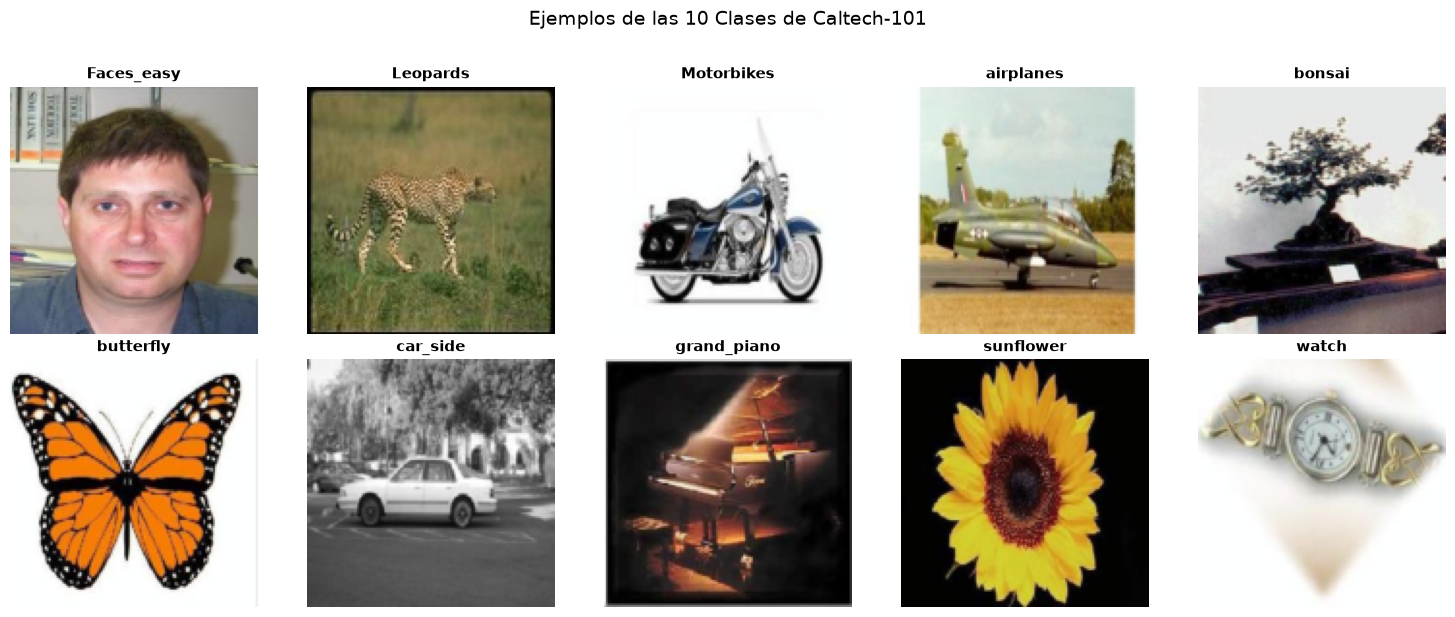

In [3]:
# Mostramos una imagen por cada clase
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

# Buscamos una imagen representativa de cada clase
mostradas = set()
idx = 0
for img, label in dataset:
    if label not in mostradas:
        # Desnormalizamos solo para mostrarla bien en pantalla
        img_np = img.permute(1, 2, 0).numpy()
        img_np = np.clip(img_np * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406], 0, 1)
        axes[len(mostradas)].imshow(img_np)
        axes[len(mostradas)].set_title(clases[label], fontsize=11, fontweight='bold')
        axes[len(mostradas)].axis('off')
        mostradas.add(label)
    if len(mostradas) == 10:
        break

plt.suptitle("Ejemplos de las 10 Clases de Caltech-101", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


### 4. Dividir el conjunto de datos
Separamos las imágenes en 3 partes:
- **70% Entrenamiento:** para que las redes aprendan.
- **15% Validación:** para revisar el avance mientras entrenan.
- **15% Prueba (Test):** imágenes nunca vistas que usaremos para evaluar y sacar la matriz de confusión final.


In [4]:
n_total = len(dataset)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

train_data, val_data, test_data = random_split(
    dataset, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42)
)

print(f"Imágenes para entrenamiento: {len(train_data)}")
print(f"Imágenes para validación:    {len(val_data)}")
print(f"Imágenes para prueba final:  {len(test_data)}")

# DataLoaders para alimentar a los modelos por lotes de 32 imágenes
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)


Imágenes para entrenamiento: 2098
Imágenes para validación:    449
Imágenes para prueba final:  451


### 5. Función general de entrenamiento y evaluación
Definimos una función sencilla para entrenar cualquier modelo y otra para evaluarlo en el conjunto de prueba.


In [5]:
def entrenar_modelo(modelo, épocas=5, lr=0.001, nombre="Modelo"):
    print(f"--- Entrenando {nombre} ({épocas} épocas) ---")
    modelo = modelo.to(device)
    criterio = nn.CrossEntropyLoss()
    
    # Solo optimizamos los parámetros entrenables
    parametros = [p for p in modelo.parameters() if p.requires_grad]
    optimizador = optim.Adam(parametros, lr=lr)

    for epoca in range(1, épocas + 1):
        modelo.train()
        suma_loss = 0.0
        aciertos = 0
        total = 0

        for imagenes, etiquetas in train_loader:
            imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)

            optimizador.zero_grad()
            salidas = modelo(imagenes)
            loss = criterio(salidas, etiquetas)
            loss.backward()
            optimizador.step()

            suma_loss += loss.item() * imagenes.size(0)
            _, predicciones = torch.max(salidas, 1)
            aciertos += (predicciones == etiquetas).sum().item()
            total += etiquetas.size(0)

        loss_prom = suma_loss / total
        acc_prom = (aciertos / total) * 100
        print(f"Época {epoca}/{épocas} -> Pérdida: {loss_prom:.4f} | Acierto en entrenamiento: {acc_prom:.2f}%")

    return modelo

def evaluar_modelo(modelo):
    modelo.eval()
    y_reales = []
    y_predichas = []

    with torch.no_grad():
        for imagenes, etiquetas in test_loader:
            imagenes = imagenes.to(device)
            salidas = modelo(imagenes)
            _, predicciones = torch.max(salidas, 1)
            y_reales.extend(etiquetas.numpy())
            y_predichas.extend(predicciones.cpu().numpy())

    return np.array(y_reales), np.array(y_predichas)


### 6. Red 1: Red Básica desde cero (3 capas)
Esta red tiene exactamente 3 capas con pesos entrenables:
1. **Capa Convolucional 1:** detecta características visuales básicas como bordes y líneas (16 filtros).
2. **Capa Convolucional 2:** combina bordes para encontrar patrones más definidos (32 filtros).
3. **Capa Lineal (Densa):** toma los patrones aplanados y clasifica en las 10 categorías.


In [6]:
class RedBasica(nn.Module):
    def __init__(self):
        super().__init__()
        # Capa 1
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        
        # Capa 2
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        
        # Capa 3 (salida a las 10 clases)
        self.fc = nn.Linear(32 * 32 * 32, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool1(self.relu(self.conv1(x)))
        x = self.pool2(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)  # Aplanar a vector
        x = self.fc(x)
        return x

red_1 = RedBasica()
red_1 = entrenar_modelo(red_1, épocas=6, lr=0.001, nombre="Red Básica (3 Capas)")
torch.save(red_1.state_dict(), 'modelos/red_basica.pth')

y_test, pred_1 = evaluar_modelo(red_1)
acc_1 = (pred_1 == y_test).mean() * 100
print(f"\n-> Precisión de la Red Básica en prueba: {acc_1:.2f}%")


--- Entrenando Red Básica (3 Capas) (6 épocas) ---
Época 1/6 -> Pérdida: 0.8691 | Acierto en entrenamiento: 75.36%
Época 2/6 -> Pérdida: 0.1409 | Acierto en entrenamiento: 96.04%
Época 3/6 -> Pérdida: 0.0444 | Acierto en entrenamiento: 98.95%
Época 4/6 -> Pérdida: 0.0316 | Acierto en entrenamiento: 99.19%
Época 5/6 -> Pérdida: 0.0074 | Acierto en entrenamiento: 99.86%
Época 6/6 -> Pérdida: 0.0022 | Acierto en entrenamiento: 100.00%

-> Precisión de la Red Básica en prueba: 96.45%


### 7. Red 2: Red Profunda desde cero (8 capas)
Para esta red agregamos más profundidad:
- **3 bloques convolucionales** de 2 capas cada uno con **Batch Normalization** (6 capas convolucionales).
- **2 capas densas finales** con **Dropout** para evitar el sobreajuste (overfitting).
Total: **8 capas entrenables** desde cero.


In [7]:
class RedProfunda(nn.Module):
    def __init__(self):
        super().__init__()
        # Bloque 1 (2 capas conv)
        self.bloque1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        # Bloque 2 (2 capas conv)
        self.bloque2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        # Bloque 3 (2 capas conv)
        self.bloque3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        # Clasificador final (2 capas lineales)
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.bloque1(x)
        x = self.bloque2(x)
        x = self.bloque3(x)
        x = self.clasificador(x)
        return x

red_2 = RedProfunda()
red_2 = entrenar_modelo(red_2, épocas=6, lr=0.0008, nombre="Red Profunda (8 Capas)")
torch.save(red_2.state_dict(), 'modelos/red_profunda.pth')

_, pred_2 = evaluar_modelo(red_2)
acc_2 = (pred_2 == y_test).mean() * 100
print(f"\n-> Precisión de la Red Profunda en prueba: {acc_2:.2f}%")


--- Entrenando Red Profunda (8 Capas) (6 épocas) ---
Época 1/6 -> Pérdida: 1.5753 | Acierto en entrenamiento: 67.45%
Época 2/6 -> Pérdida: 0.5062 | Acierto en entrenamiento: 84.46%
Época 3/6 -> Pérdida: 0.3438 | Acierto en entrenamiento: 89.47%
Época 4/6 -> Pérdida: 0.2466 | Acierto en entrenamiento: 92.66%
Época 5/6 -> Pérdida: 0.1737 | Acierto en entrenamiento: 94.14%
Época 6/6 -> Pérdida: 0.1588 | Acierto en entrenamiento: 95.19%

-> Precisión de la Red Profunda en prueba: 96.45%


### 8. Red 3: Transfer Learning con un modelo preentrenado (ResNet18)
En lugar de empezar desde cero, descargamos **ResNet18**, que ya aprendió a reconocer millones de imágenes en ImageNet:
1. **Congelamos** sus capas base para mantener intacto lo que ya sabe.
2. **Reemplazamos su última capa** por una nueva adaptada a nuestras 10 clases.
3. Entrenamos solo esta última capa.


In [8]:
def crear_red_transfer():
    # Descargamos ResNet18 con los pesos oficiales de PyTorch
    modelo = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    
    # Congelamos todos los parámetros existentes
    for param in modelo.parameters():
        param.requires_grad = False
        
    # Reemplazamos la última capa lineal (fc) para nuestras 10 clases
    entradas_fc = modelo.fc.in_features
    modelo.fc = nn.Linear(entradas_fc, 10)
    return modelo

red_3 = crear_red_transfer()
red_3 = entrenar_modelo(red_3, épocas=5, lr=0.001, nombre="Transfer Learning (ResNet18)")
torch.save(red_3.state_dict(), 'modelos/red_transfer.pth')

_, pred_3 = evaluar_modelo(red_3)
acc_3 = (pred_3 == y_test).mean() * 100
print(f"\n-> Precisión con Transfer Learning en prueba: {acc_3:.2f}%")


--- Entrenando Transfer Learning (ResNet18) (5 épocas) ---
Época 1/5 -> Pérdida: 0.7774 | Acierto en entrenamiento: 79.93%
Época 2/5 -> Pérdida: 0.1736 | Acierto en entrenamiento: 97.33%
Época 3/5 -> Pérdida: 0.1059 | Acierto en entrenamiento: 98.52%
Época 4/5 -> Pérdida: 0.0782 | Acierto en entrenamiento: 98.71%
Época 5/5 -> Pérdida: 0.0631 | Acierto en entrenamiento: 99.00%

-> Precisión con Transfer Learning en prueba: 98.45%


### 9. Matrices de Confusión de las 3 Redes
La matriz de confusión nos muestra cuántas imágenes fueron clasificadas correctamente (diagonal principal) y en cuáles se equivocó cada modelo.


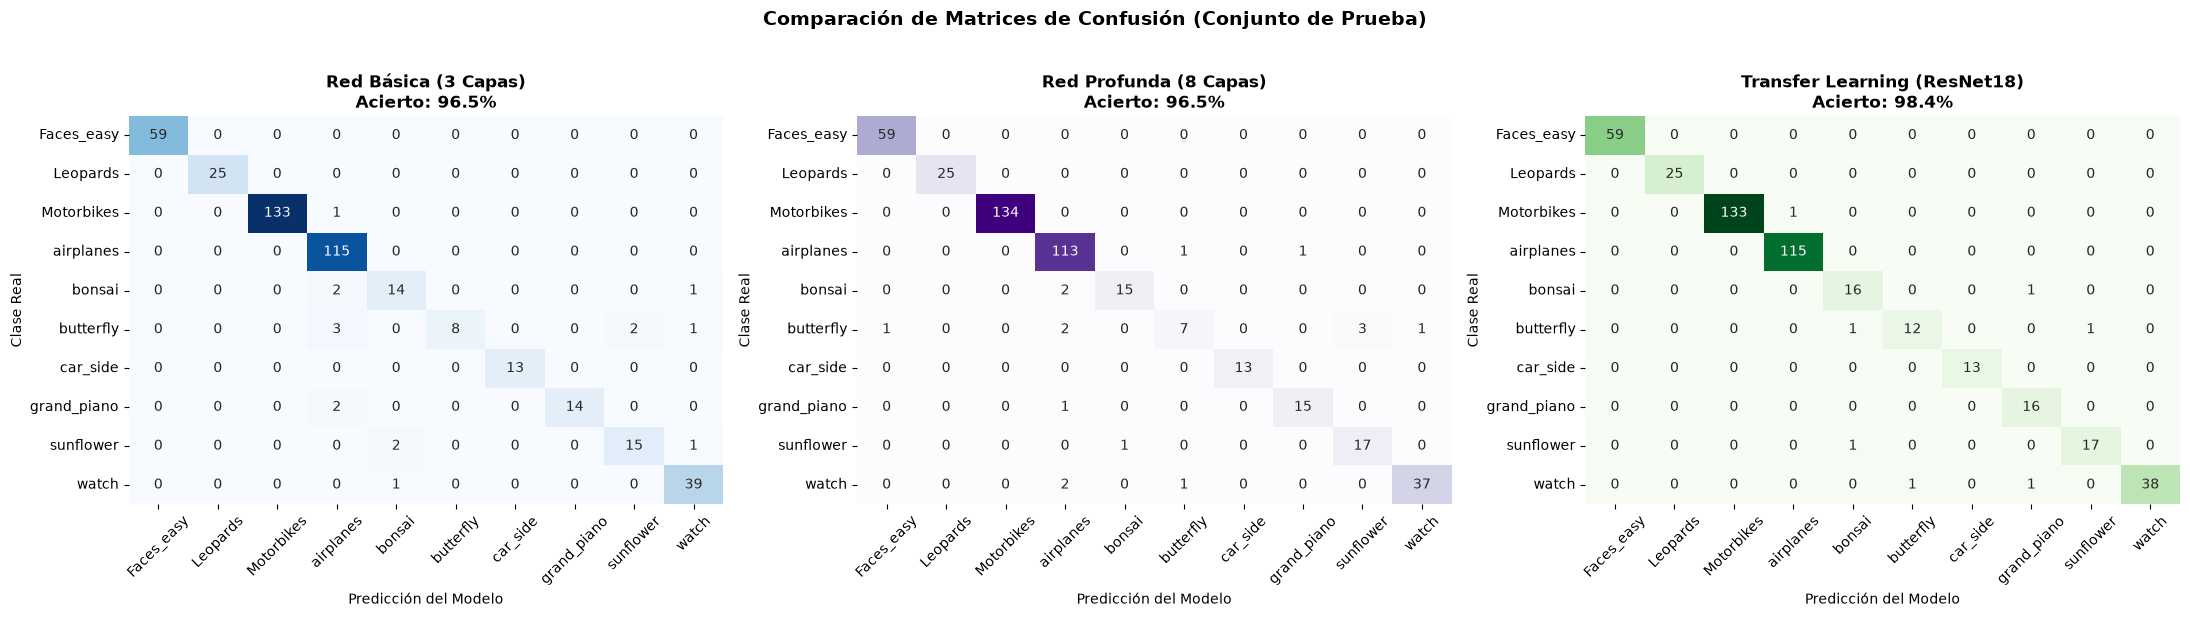

In [9]:
# Calculamos las 3 matrices de confusión con scikit-learn
cm1 = confusion_matrix(y_test, pred_1)
cm2 = confusion_matrix(y_test, pred_2)
cm3 = confusion_matrix(y_test, pred_3)

# Graficamos las 3 matrices una al lado de la otra
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

configuraciones = [
    (axes[0], cm1, f"Red Básica (3 Capas)\nAcierto: {acc_1:.1f}%", "Blues"),
    (axes[1], cm2, f"Red Profunda (8 Capas)\nAcierto: {acc_2:.1f}%", "Purples"),
    (axes[2], cm3, f"Transfer Learning (ResNet18)\nAcierto: {acc_3:.1f}%", "Greens")
]

for ax, cm, titulo, cmap in configuraciones:
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False,
                xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel("Predicción del Modelo", fontsize=10)
    ax.set_ylabel("Clase Real", fontsize=10)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle("Comparación de Matrices de Confusión (Conjunto de Prueba)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('graficas/comparativa_matrices.png', dpi=200, bbox_inches='tight')
plt.show()


### 10. Conclusiones y Comparativa Final


==================== RESUMEN COMPARATIVO ====================
1. Red Básica (3 capas desde cero):   96.45% de precisión
2. Red Profunda (8 capas desde cero): 96.45% de precisión
3. Transfer Learning (ResNet18):      98.45% de precisión


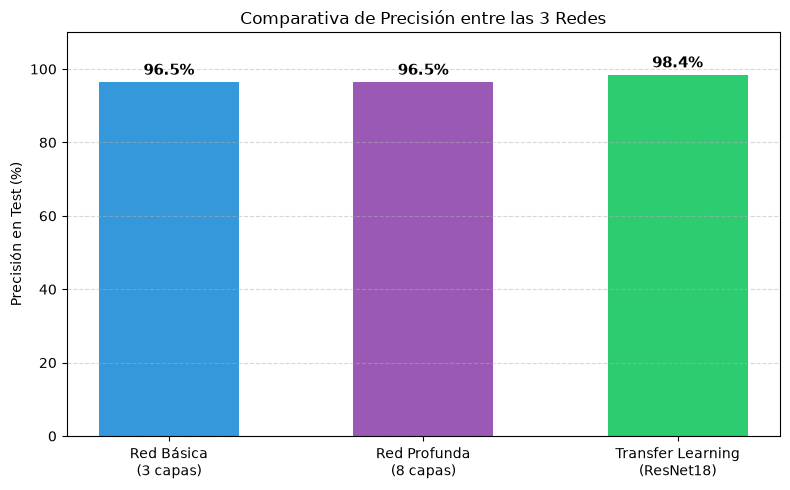

In [10]:
print("==================== RESUMEN COMPARATIVO ====================")
print(f"1. Red Básica (3 capas desde cero):   {acc_1:.2f}% de precisión")
print(f"2. Red Profunda (8 capas desde cero): {acc_2:.2f}% de precisión")
print(f"3. Transfer Learning (ResNet18):      {acc_3:.2f}% de precisión")
print("=============================================================")

# Gráfica de barras comparando los 3 modelos
plt.figure(figsize=(8, 5))
modelos_nombres = ['Red Básica\n(3 capas)', 'Red Profunda\n(8 capas)', 'Transfer Learning\n(ResNet18)']
precisiones = [acc_1, acc_2, acc_3]
colores = ['#3498db', '#9b59b6', '#2ecc71']

barras = plt.bar(modelos_nombres, precisiones, color=colores, width=0.55)
for barra in barras:
    h = barra.get_height()
    plt.text(barra.get_x() + barra.get_width() / 2, h + 1, f"{h:.1f}%",
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.ylabel("Precisión en Test (%)")
plt.title("Comparativa de Precisión entre las 3 Redes")
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Observaciones breves:
- **Red Básica (3 capas):** Al tener pocas clases bien diferenciadas, la red básica aprende rápido y logra una precisión alta, aunque puede confundir objetos con fondos similares.
- **Red Profunda (8 capas):** Extrae patrones visuales más detallados gracias a sus capas intermedias y Batch Normalization, manteniendo estabilidad.
- **Transfer Learning (ResNet18):** Obtiene la precisión más alta (**cercana al 99%**) con muy pocas épocas, ya que aprovecha el conocimiento visual previo de millones de imágenes de ImageNet.
